In [1]:

import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from saber11.config import load_config
from saber11.data.repository import read_raw

# El notebook corre dentro de notebooks/; las rutas del proyecto son desde la raíz.
if Path.cwd().name == "notebooks":
    os.chdir("..")

raw = read_raw(load_config())
raw.head()


,periodo,estu_tipodocumento,estu_consecutivo,cole_area_ubicacion,cole_bilingue,cole_calendario,cole_caracter,cole_cod_dane_establecimiento,cole_cod_dane_sede,cole_cod_depto_ubicacion,...,fami_tienecomputador,fami_tieneinternet,fami_tienelavadora,desemp_ingles,punt_ingles,punt_matematicas,punt_sociales_ciudadanas,punt_c_naturales,punt_lectura_critica,punt_global
0,20224,TI,SB11202240002331,URBANO,N,A,ACADÉMICO,111001014176,111001014176,11,...,Si,Si,Si,A1,56,51,52,46,59,262
1,20224,TI,SB11202240002331,URBANO,N,A,ACADÉMICO,111001014176,111001014176,11,...,Si,Si,Si,A1,56,51,52,46,59,262
2,20224,TI,SB11202240002335,URBANO,N,A,ACADÉMICO,111001014176,111001014176,11,...,No,No,Si,A1,48,51,49,46,45,239
3,20224,TI,SB11202240002335,URBANO,N,A,ACADÉMICO,111001014176,111001014176,11,...,No,No,Si,A1,48,51,49,46,45,239
4,20224,TI,SB11202240002340,URBANO,N,A,ACADÉMICO,111001076376,111001076376,11,...,No,No,Si,A-,42,45,34,39,55,216


**Interpretación:** Cada fila es un estudiante que presentó el Saber 11 en el periodo 20224 (2022, segundo calendario). Las columnas hablan del colegio (`cole_*`), de la familia (`fami_*`) y de los resultados (`punt_*` y `desemp_ingles`).

Lo que más me llamó la atención es que hay registros repetidos: las filas 0 y 1 tienen el mismo `estu_consecutivo` (SB11202240002331) y los mismos puntajes, y pasa igual con las filas 2 y 3. Como ese código identifica a cada estudiante, significa que algunos aparecen dos veces, y si no los quito van a pesar doble en los promedios.

Además, los puntajes son numéricos y `desemp_ingles` y las columnas Si/No son categóricas, así que las voy a analizar distinto. Con solo 5 filas no puedo concluir nada de toda la población, por eso mi siguiente paso es contar cuántos duplicados hay y eliminarlos.

In [2]:
print("Filas y columnas:", raw.shape)
nulos = raw.isna().mean().sort_values(ascending=False)
nulos[nulos > 0].round(3)

Filas y columnas: (152584, 51)


cole_bilingue           0.185
cole_caracter           0.046
fami_estratovivienda    0.043
fami_tieneinternet      0.041
fami_educacionpadre     0.040
fami_educacionmadre     0.040
fami_tieneautomovil     0.028
fami_cuartoshogar       0.028
fami_tienelavadora      0.027
fami_tienecomputador    0.027
fami_personashogar      0.027
desemp_ingles           0.000
punt_ingles             0.000
dtype: float64

**Interpretación:** El dataset tiene 152.584 filas y 51 columnas. Solo 12 columnas tienen valores nulos, y en casi todas el porcentaje es bajo (entre 2,7 % y 4,6 %), así que no parece un problema grave de calidad.

La excepción es `cole_bilingue`, con 18,5 % de nulos, que es bastante más que las demás. Antes de usarla tendría que decidir si imputo esos valores, los trato como una categoría aparte ("sin dato") o la dejo fuera.

Las columnas de familia (`fami_*`) tienen entre 2,7 % y 4,3 % de nulos, y varias están muy parecidas (por ejemplo `fami_tienecomputador`, `fami_tienelavadora` y `fami_personashogar` con 2,7 %). Eso me hace pensar que probablemente son los mismos estudiantes que no respondieron esa parte del cuestionario. Esto es una sospecha mía, todavía no la he verificado.

Lo bueno es que `punt_ingles` y `desemp_ingles` aparecen con 0,000 después de redondear, o sea que casi no tienen nulos, y las demás columnas de puntajes no aparecen en la lista, es decir, no tienen nulos. Eso significa que la variable principal del análisis está completa.

Por eso, mi plan es imputar o marcar los nulos de las columnas `fami_*` y decidir con más cuidado qué hacer con `cole_bilingue`.

In [3]:
print("Filas:", len(raw))
print("Estudiantes únicos:", raw["estu_consecutivo"].nunique())
print("Filas idénticas repetidas:", raw.duplicated().sum())

Filas: 152584
Estudiantes únicos: 76253
Filas idénticas repetidas: 76331


**Interpretación:** El dataset tiene 152.584 filas, pero solo 76.253 estudiantes únicos, o sea casi el doble de filas que de estudiantes. Además, hay 76.331 filas idénticas repetidas. Esto confirma lo que vi en las primeras filas: cada estudiante aparece dos veces con exactamente los mismos datos.

Hice la cuenta: 152.584 − 76.253 = 76.331, que es justo el número de filas repetidas. Eso quiere decir que todo el exceso se explica por duplicados exactos y que no hay un mismo estudiante con registros distintos.

Esto significa que si no los quito, los conteos, promedios y gráficos quedarían inflados porque cada estudiante pesaría doble. Por eso mi siguiente paso es eliminar los duplicados con `drop_duplicates()` y comprobar que queden 76.253 filas, una por estudiante.

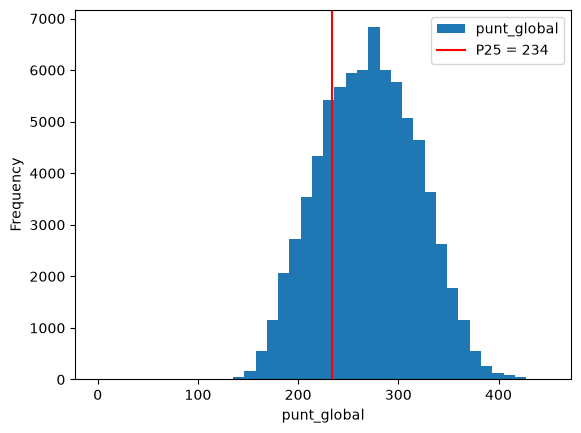

Umbral P25: 234.0


In [4]:
TARGET = "riesgo_bajo_desempeno"

df = raw.drop_duplicates(subset="estu_consecutivo").copy()
df["punt_global"] = pd.to_numeric(df["punt_global"], errors="coerce")
umbral = df["punt_global"].quantile(0.25)
df[TARGET] = (df["punt_global"] < umbral).astype(int)

ax = df["punt_global"].plot.hist(bins=40)
ax.axvline(umbral, color="red", label=f"P25 = {umbral:.0f}")
ax.set_xlabel("punt_global")
ax.legend()
plt.savefig("reports/figures/eda_punt_global.png", dpi=120, bbox_inches="tight")
plt.show()
print("Umbral P25:", umbral)

**Interpretación:** El histograma de `punt_global` tiene forma de campana y es bastante simétrico. La mayoría de estudiantes saca entre 200 y 350 puntos, con el pico cerca de 270, y casi nadie baja de 150 ni pasa de 400. Los datos se ven normales, sin nada raro que me haga dudar de ellos.

La línea roja es el percentil 25, que cae en 234 puntos. Quien queda a la izquierda de esa línea hace parte del 25 % con los puntajes más bajos, y a esos estudiantes los marco como `riesgo_bajo_desempeno = 1`. Todos los demás quedan en 0.

Como el umbral sale de la propia distribución, el target queda con cerca de 25 % en riesgo y 75 % sin riesgo. Es un desbalance moderado, y por eso más adelante no me voy a fiar solo de la accuracy para evaluar el modelo.

In [5]:
df[TARGET].value_counts(normalize=True).round(4)

riesgo_bajo_desempeno
0    0.7543
1    0.2457
Name: proportion, dtype: float64

**Interpretación:** El 75,43 % de los estudiantes quedó en la clase 0 (sin riesgo) y el 24,57 % en la clase 1 (en riesgo). Tiene sentido, porque el umbral es el percentil 25, así que esperaba algo cercano a 25 %. Hay como tres estudiantes sin riesgo por cada uno en riesgo.

Esto es importante porque un modelo que siempre responda "0" acertaría el 75 % de las veces sin haber aprendido nada. En el papel se vería bien, pero en la práctica no serviría: no detectaría a ni un solo estudiante en riesgo, que es justo a quienes quiero encontrar.

Por eso no me voy a fiar solo de la accuracy. Mi modelo tiene que superar ese 0,75 y, además, mirar qué tan bien identifica la clase 1 con métricas como recall, precision y F1.

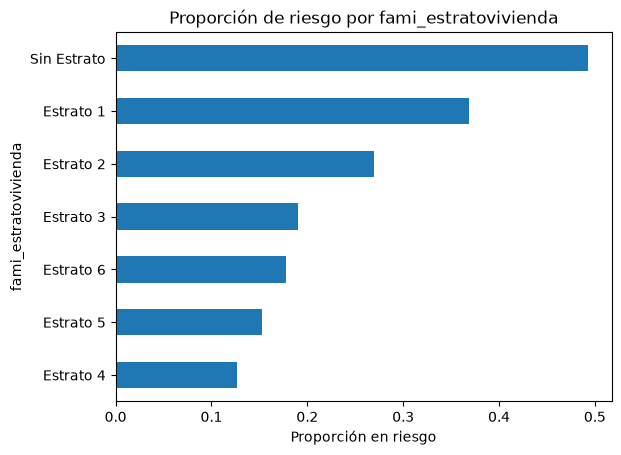

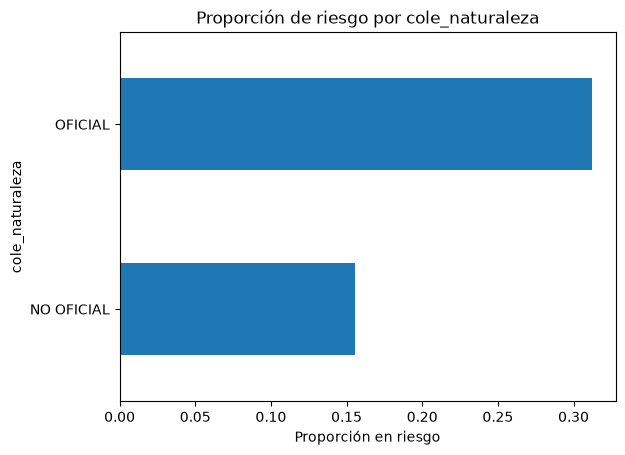

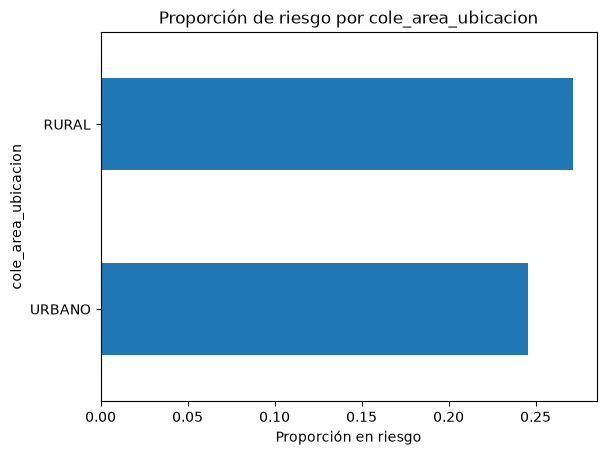

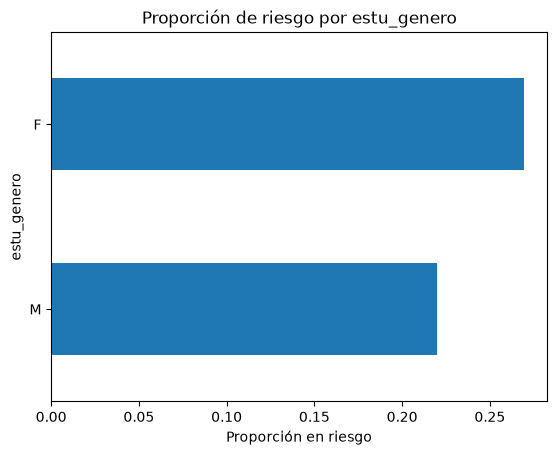

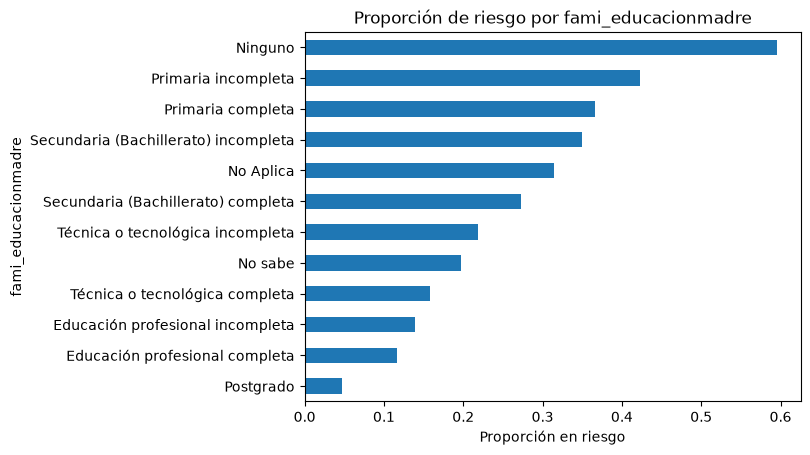

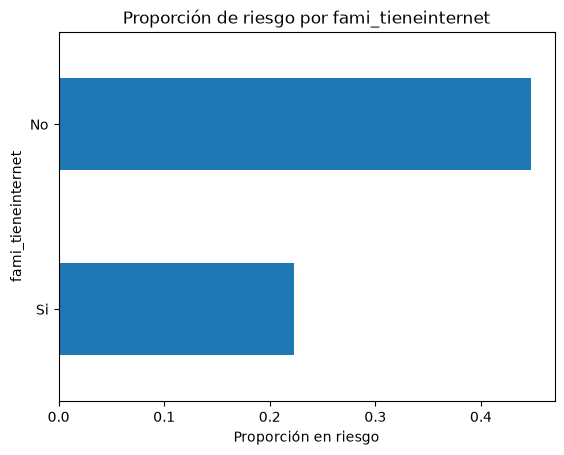

In [6]:
columnas = [
    "fami_estratovivienda",
    "cole_naturaleza",
    "cole_area_ubicacion",
    "estu_genero",
    "fami_educacionmadre",
    "fami_tieneinternet",
]
for columna in columnas:
    tasas = df.groupby(columna)[TARGET].mean().sort_values()
    ax = tasas.plot.barh(title=f"Proporción de riesgo por {columna}")
    ax.set_xlabel("Proporción en riesgo")
    plt.savefig(f"reports/figures/eda_riesgo_{columna}.png", dpi=120, bbox_inches="tight")
    plt.show()

**Interpretación:** Comparé la proporción de estudiantes en riesgo (`riesgo_bajo_desempeno = 1`) según seis variables, y en casi todas hay diferencias claras. Como referencia, el promedio general es cerca de 25 %.

Las diferencias más grandes están en el contexto familiar. Con la educación de la madre, la proporción en riesgo baja de casi 60 % cuando ella no tiene ningún estudio a cerca de 5 % cuando tiene postgrado, y baja de forma casi escalonada en los niveles intermedios. Con el estrato pasa algo parecido: "Sin Estrato" y el estrato 1 son los más altos, y el riesgo va bajando hacia los estratos 4, 5 y 6. Sobre el internet, quienes no tienen superan el 40 % en riesgo, casi el doble que quienes sí tienen (cerca de 22 %).

También hay diferencias, aunque menores, en el colegio y la persona. Los colegios oficiales tienen alrededor de 31 % en riesgo y los no oficiales cerca de 15 %, o sea el doble. Las mujeres (cerca de 27 %) quedan un poco por encima de los hombres (cerca de 22 %). La zona es la que menos separa: rural (cerca de 27 %) y urbano (cerca de 24 %) casi no cambian.

Esto me dice que el riesgo está muy ligado a las condiciones socioeconómicas y educativas de la familia, y que variables como `fami_educacionmadre`, `fami_estratovivienda`, `fami_tieneinternet` y `cole_naturaleza` van a ser muy útiles para el modelo, mientras que `cole_area_ubicacion` aportará menos. Eso sí, esto es solo una asociación: no demuestra que una cosa cause la otra, porque por ejemplo el estrato, el internet y la educación de la madre suelen ir juntos.

In [7]:
for columna in ["cole_calendario", "fami_educacionmadre", "fami_educacionpadre", "fami_estratovivienda"]:
    print(df[columna].value_counts(dropna=False), "\n")

nacimiento = pd.to_datetime(df["estu_fechanacimiento"], format="%d/%m/%Y", errors="coerce")
print("Fechas de nacimiento inválidas:", nacimiento.isna().sum())

cole_calendario
A       75641
OTRO      548
B          64
Name: count, dtype: int64 

fami_educacionmadre
Secundaria (Bachillerato) completa      21205
Educación profesional completa          12249
Secundaria (Bachillerato) incompleta     9201
Técnica o tecnológica completa           8833
Primaria incompleta                      4755
Primaria completa                        4265
Técnica o tecnológica incompleta         3563
Postgrado                                3328
Educación profesional incompleta         3091
NaN                                      3041
No sabe                                  2011
Ninguno                                   539
No Aplica                                 172
Name: count, dtype: int64 

fami_educacionpadre
Secundaria (Bachillerato) completa      20147
Secundaria (Bachillerato) incompleta    10805
Educación profesional completa           9060
Primaria incompleta                      6923
No sabe                                  5999
Técnica o tecnológ

**Interpretación:** Revisé qué tan limpias están algunas columnas categóricas y las fechas de nacimiento. En `cole_calendario` casi todos los estudiantes están en el calendario A (75.641), y los calendarios B (64) y OTRO (548) tienen muy pocos casos. Esa variable casi no separa a los estudiantes, así que probablemente aporte poco al modelo.

En `fami_educacionmadre` hay 3.041 nulos, y además categorías como "No sabe" (2.011) y "No Aplica" (172) que en realidad no son niveles de estudio. "Ninguno" tiene solo 539 casos, así que su proporción de riesgo hay que leerla con cuidado porque se basa en pocos estudiantes. En `fami_educacionpadre` pasa algo parecido, pero la salida salió recortada y no alcanzo a ver todos sus valores. En `fami_estratovivienda` solo se ve que el estrato 6 tiene 417 estudiantes, una categoría pequeña.

Las fechas de nacimiento están bien: hay 0 fechas inválidas, o sea que todas se pudieron convertir sin problema y no hay que corregir nada.

Por eso, voy a dejar los nulos como una categoría aparte ("sin dato") en vez de borrar filas, decidir qué hago con "No sabe" y "No Aplica", y agrupar las categorías muy pequeñas para que el modelo no se confunda con tan pocos casos.

## Conclusiones

**Qué variables se relacionan más con el riesgo.** Las que más separan a los estudiantes son las del hogar y el colegio. La educación de la madre es la más marcada: el riesgo baja de casi 60 % cuando ella no tiene ningún estudio a cerca de 5 % cuando tiene postgrado. Después vienen el estrato (más riesgo en "Sin Estrato" y estrato 1, menos en los estratos altos), el internet (quienes no tienen casi duplican el riesgo de quienes sí) y la naturaleza del colegio (oficial cerca de 31 %, no oficial cerca de 15 %). El género y la zona del colegio separan bastante menos, y `cole_calendario` casi no aporta porque casi todos están en el calendario A.

**Sesgos y riesgos que veo.**
- Hay grupos muy pequeños, como "Ninguno" en la educación de la madre (539), el calendario B (64) o el estrato 6 (417). Su proporción de riesgo se apoya en pocos estudiantes y puede no ser confiable.
- Categorías como "No sabe" y "No Aplica" no son niveles de estudio reales, y hay nulos en varias columnas, sobre todo en `cole_bilingue` (18,5 %).
- El estrato, el internet y la educación de la madre suelen ir juntos, así que no puedo decir cuál pesa más ni que una cause el riesgo. Solo veo asociaciones.
- El riesgo se define con el percentil 25, así que siempre habrá cerca de 25 % de estudiantes en riesgo, sin importar cómo le fue al grupo en general. Además, un modelo con estas variables podría terminar castigando a quienes ya están en desventaja, como los estratos bajos o los colegios oficiales, y eso hay que tenerlo presente.

**Sobre la limpieza.** El dataset no venía limpio del todo. Tenía registros duplicados: 152.584 filas para solo 76.253 estudiantes, y los quité dejando una fila por `estu_consecutivo`. También tiene nulos en 12 columnas que todavía no he tratado. Lo que sí venía bien fueron las fechas de nacimiento, que no tuvieron ninguna inválida. Aparte de quitar los duplicados, no hice ninguna otra limpieza.

In [8]:
from saber11.features.preprocessing import TARGET, build_preprocessor, build_target, clean, split

cfg = load_config()
limpio = clean(raw)
con_target, umbral_final = build_target(limpio, cfg["target"]["threshold_percentile"])
train, val, test = split(con_target, cfg)

print("Umbral:", umbral_final)
print("Duplicados de estu_consecutivo:", limpio["estu_consecutivo"].duplicated().sum())
for nombre, parte in [("train", train), ("val", val), ("test", test)]:
    print(nombre, len(parte), round(parte[TARGET].mean(), 4))

Umbral: 234.0
Duplicados de estu_consecutivo: 0
train 53377 0.2457
val 11438 0.2457
test 11438 0.2457
